In [ ]:
!apt-get update -qq
!apt-get install -y g++ libopencv-dev libcurl4-openssl-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
g++ is already the newest version (4:13.2.0-7ubuntu1).
g++ set to manually installed.
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1

Эксперименты с разными фотографиями

In [ ]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}


cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {

    std::string source = (argc > 1) ? argv[1]
        : "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";


    std::string output = (argc > 2) ? argv[2] : "faces_detected.jpg";

    std::cout << "Loading: " << source << std::endl;
    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Failed to load image from: " << source << std::endl;
        return 1;
    }
    std::cout << "Image: " << image.cols << "x" << image.rows << std::endl;


    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Cannot load cascades" << std::endl;
        return 1;
    }


    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);


    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(
        gray, faces,
          1.05,
          5,
          0,
          cv::Size(20, 20)
    );

    std::cout << "Detected faces: " << faces.size() << std::endl;


    int idx = 0;
    size_t total_eyes = 0;
    for (const auto& face : faces) {
        ++idx;
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);


        std::string label = "Face " + std::to_string(idx);
        int baseline = 0;
        cv::Size text_size = cv::getTextSize(label, cv::FONT_HERSHEY_SIMPLEX, 0.6, 2, &baseline);
        cv::Point text_org(face.x, face.y - 5);
        if (text_org.y < text_size.height) text_org.y = face.y + text_size.height + 5;

        cv::rectangle(image,
                      cv::Point(text_org.x, text_org.y - text_size.height - 2),
                      cv::Point(text_org.x + text_size.width, text_org.y + 2),
                      cv::Scalar(0, 255, 0), cv::FILLED);
        cv::putText(image, label, text_org, cv::FONT_HERSHEY_SIMPLEX, 0.6,
                    cv::Scalar(0, 0, 0), 2);


        cv::Mat face_roi_gray  = gray(face);
        cv::Mat face_roi_gray_top = face_roi_gray(cv::Rect(0, 0, face.width, face.height * 6 / 10));

        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(face_roi_gray_top, eyes, 1.1, 10);
        total_eyes += eyes.size();
        for (const auto& eye : eyes) {
            cv::Rect eye_abs(face.x + eye.x, face.y + eye.y, eye.width, eye.height);
            cv::rectangle(image, eye_abs, cv::Scalar(255, 0, 0), 2);
        }
    }

    std::cout << "Detected eyes: " << total_eyes << std::endl;

    cv::imwrite(output, image);
    std::cout << "Result saved: " << output << std::endl;

    if (faces.empty()) {
        std::cerr << "No faces detected. Try another image or lower minNeighbors." << std::endl;
        return 2;
    }
    return 0;
}

Overwriting detect_faces.cpp


In [ ]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17

In [ ]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

def show(path, title):
    img = cv2.imread(path)
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

### Эксперимент 1: один человек анфас

In [ ]:
uploaded = files.upload()
photo1 = list(uploaded.keys())[0]

Saving 12736811441012350.jpg to 12736811441012350 (1).jpg


In [ ]:
!./detect_faces "{photo1}" result1.jpg

Loading: 12736811441012350 (1).jpg
Image: 400x545
Detected faces: 1
Detected eyes: 2
Result saved: result1.jpg


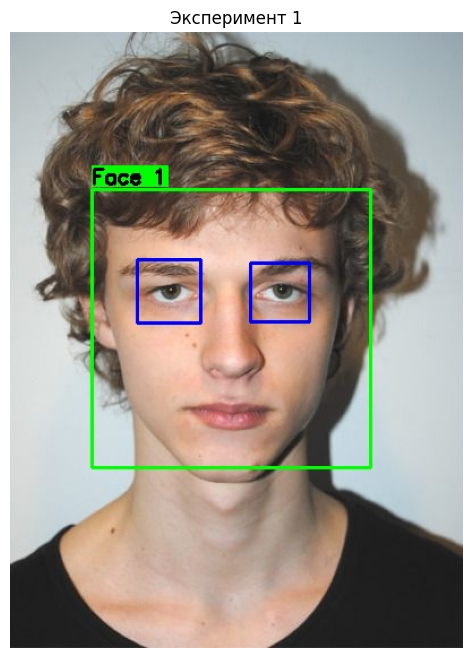

In [ ]:
show('result1.jpg', 'Эксперимент 1')

### Эксперимент 2: групповое фото

In [ ]:
uploaded = files.upload()
photo2 = list(uploaded.keys())[0]

Saving The Studio.jpg to The Studio.jpg


In [ ]:
!./detect_faces "{photo2}" result2.jpg

Loading: The Studio.jpg
Image: 736x1308
Detected faces: 6
Detected eyes: 0
Result saved: result2.jpg


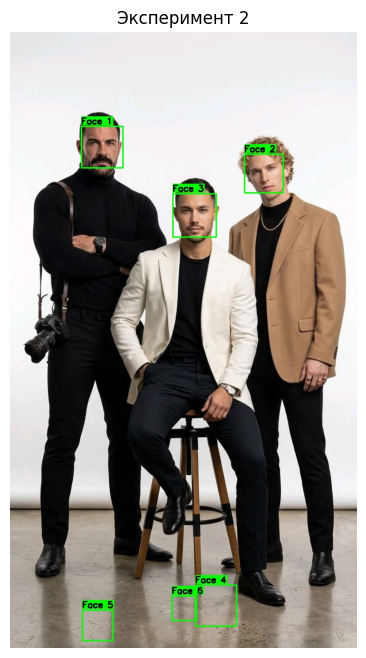

In [ ]:
show('result2.jpg', 'Эксперимент 2')

### Эксперимент 3: профиль или наклон головы

In [ ]:
uploaded = files.upload()
photo3 = list(uploaded.keys())[0]

Saving photo_2026-11-25 23.48.29.jpeg to photo_2026-11-25 23.48.29.jpeg


In [ ]:
!./detect_faces "{photo3}" result3.jpg

Loading: photo_2026-11-25 23.48.29.jpeg
Image: 264x404
Detected faces: 0
Detected eyes: 0
Result saved: result3.jpg
No faces detected. Try another image or lower minNeighbors.


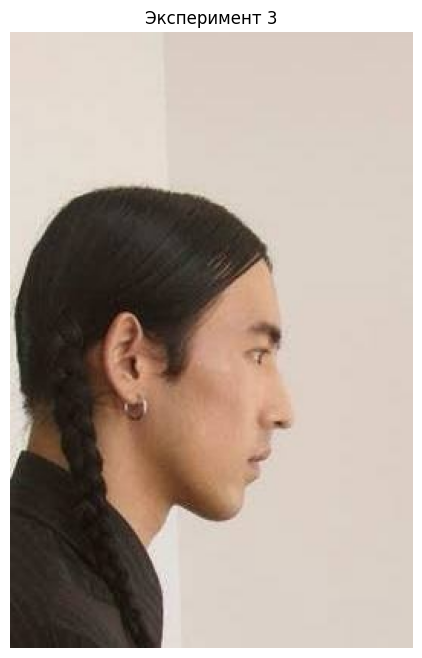

In [ ]:
show('result3.jpg', 'Эксперимент 3')

### Эксперимент 4: очки или плохое освещение

In [ ]:
uploaded = files.upload()
photo4 = list(uploaded.keys())[0]

Saving #cinematic #photoshoot #cinematicphotography #portrait #cinematicportrait #rgb #rgbphotoshoot #nightphotography #nightphotoshoot .jpg to #cinematic #photoshoot #cinematicphotography #portrait #cinematicportrait #rgb #rgbphotoshoot #nightphotography #nightphotoshoot .jpg


In [ ]:
!./detect_faces "{photo4}" result4.jpg

Loading: #cinematic #photoshoot #cinematicphotography #portrait #cinematicportrait #rgb #rgbphotoshoot #nightphotography #nightphotoshoot .jpg
Image: 736x1104
Detected faces: 1
Detected eyes: 1
Result saved: result4.jpg


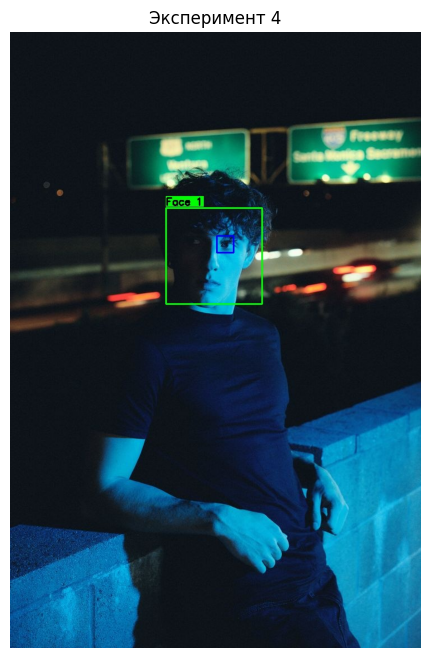

In [ ]:
show('result4.jpg', 'Эксперимент 4')

## Сравнение

| Эксперимент | Лиц на фото | Лиц найдено | Глаз на фото | Глаз найдено |
|---|---|---|---|---|
| 1. Анфас | 1 | 1 | 2 | 2 |
| 2. Групповое фото | 3 | 6 (3 верных, 3 ложных) | 6 | 0 |
| 3. Профиль | 1 | 0 | 1 | 0 |
| 4. Плохое освещение | 1 | 1 | 2 | 1 |

## Почему так получается
Каскады Хаара не «понимают» изображение, а ищут характерные перепады яркости (например, область глаз темнее щёк и переносицы).

1. **Анфас:** всё найдено верно. Лицо крупное, прямое, равномерно освещено, а каскады обучены именно на таких изображениях.
2. **Групповое фото:** все три лица найдены, но есть три ложных срабатывания на полу: пятна на бетоне образуют перепады яркости, похожие на лицо. Этому способствуют `equalizeHist` (усиливает контраст), малый `scaleFactor = 1.05` (проверяется больше масштабов) и `minSize = 20×20`. Глаза не найдены, потому что лица занимают мало пикселей, глаза получаются мелкими и нечёткими, а `minNeighbors = 10` задаёт строгий отбор.
3. **Профиль:** лицо не найдено, так как каскад `frontalface` обучен только на лицах анфас. Глаза ищутся лишь внутри найденного лица, поэтому и их 0. Для профиля есть отдельный каскад `haarcascade_profileface.xml`.
4. **Плохое освещение:** лицо найдено, но только один глаз. Вторая половина лица в тени, перепады яркости там слабые.

**Вывод:** каскады Хаара хорошо работают с крупными, прямыми и хорошо освещёнными лицами. Поворот головы, тени, малый размер и пёстрый фон приводят к пропускам и ложным срабатываниям. Увеличение `minNeighbors` для лиц может убрать ложные рамки, а уменьшение для глаз может помочь найти пропущенные, но повышает риск ошибок.